**Computing the derivatives manually:**

---



**1.** $y=x^2$

In [15]:
#We define a function of the derivative
def dy_dx(x):
  return 2*x

In [16]:
#We invoke the function defined above, to find the derivative value at x=3
dy_dx(3)

6

**Computing the derivatives using autograd:**

---



In [17]:
#Importing the required lbrary
import torch

In [18]:
x = torch.tensor(3.0, requires_grad=True) #We actually want the value of derivative at x=3

By setting the attribute *requires_grad* to *True*, PyTorch understands that we want to determine the derivatice of this tensor. It will keep tracking all the operations that we do ahead with this tensor

In [19]:
#Defining the relation between x and y
y = x**2

In [20]:
#Displaying x
x

tensor(3., requires_grad=True)

In [21]:
#Displaying y
y

tensor(9., grad_fn=<PowBackward0>)

On printing y, not only y gets calculated but it returns an attribute *grad_fn=(PowBackward0)*

Whenever we set *requires_grad* to *True*, Python internally makes a computation graph (drawn on notes)

We're passing x as a tensor, applying a power operation on it, to get y

In the Forward Direction, we calculate y with the help of x

In the Backward Direction, PyTorch gives us dy/dx, and in order to do so, it must know which mathematical operation was performed on x to give y

That's why, when printing y it has remebered that on the back side, there's a POW function been performed on x

In [22]:
y.backward()

Using the above function, the derivative gets computed automatically, and in order to find the derivative value at a particular point, we do following:

In [13]:
x.grad

tensor(6.)

**Computing the derivatives manually:**

---



**2.** $y=x^2 ; z=sin(y)$

In [23]:
#We define a function of the derivative
import math

def dz_dx(x):
    return 2 * x * math.cos(x**2)

In [24]:
#We invoke the function defined above, to find the derivative value at x=3
dz_dx(3)

-5.466781571308061

**Computing the derivatives using autograd:**

---



In [25]:
x = torch.tensor(3.0, requires_grad=True) #We actually want the value of derivative at x=3

In [26]:
#Defining the relation between x and y
y = x ** 2

In [27]:
#Defining the relation between y and z
z = torch.sin(y) #We can use PyTorch to form trigonometric functions as well

In [28]:
#Displaying x
x

tensor(3., requires_grad=True)

In [29]:
#Displaying y
y

tensor(9., grad_fn=<PowBackward0>)

In [30]:
#Displaying z
z

tensor(0.4121, grad_fn=<SinBackward0>)

The computation graph for this also is shown on notes

In [31]:
z.backward()

In [32]:
x.grad

tensor(-5.4668)

As evident, on computing the gradient, it calculates all the intermediate gradients, multiplies them together and gives the final result

Using Autograd, we're unable to calculate gradients with respect to intermediate nodes. We're only able to do it with respect to leaf nodes. That's why the following line of code throws an error

In [33]:
y.grad

/tmp/ipykernel_1906/486760323.py:1: UserWarning: The .grad attribute of a Tensor that is not a leaf Tensor is being accessed. Its .grad attribute won't be populated during autograd.backward(). If you indeed want the .grad field to be populated for a non-leaf Tensor, use .retain_grad() on the non-leaf Tensor. If you access the non-leaf Tensor by mistake, make sure you access the leaf Tensor instead. See github.com/pytorch/pytorch/pull/30531 for more information. (Triggered internally at /pytorch/build/aten/src/ATen/core/TensorBody.h:494.)
  y.grad


**Computing the derivatives manually:**

---



**3.** In the following example, consider CGPA value of 6.7 as input and the placement status as 0

We have to train the nerual network on this data

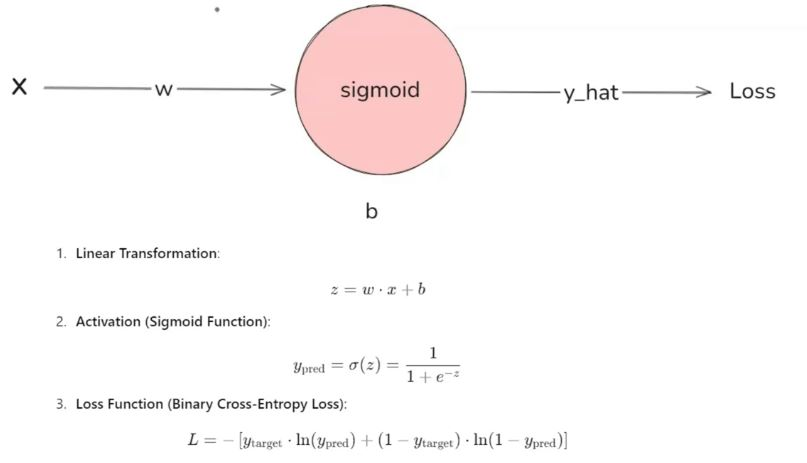

Here, we need to calculate two derivatives - **1.** Derivative of Loss wrt 'w' **2.** Derivative of Loss wrt 'b'

Loss is a nested function, and therefore these derivatives will be computed using Chain Rule of differentiation, as shown on the notes

In [35]:
import torch

# Inputs
x = torch.tensor(6.7)  # Input feature
y = torch.tensor(0.0)  # True label (binary)

# We assume the weight and bias of the neural network
w = torch.tensor(1.0)  # Weight
b = torch.tensor(0.0)  # Bias

In [36]:
# Binary Cross-Entropy Loss for scalar
def binary_cross_entropy_loss(prediction, target):
    epsilon = 1e-8  # To prevent log(0)
    prediction = torch.clamp(prediction, epsilon, 1 - epsilon)
    return -(target * torch.log(prediction) + (1 - target) * torch.log(1 - prediction))

In [37]:
# Forward pass
z = w * x + b  # Weighted sum (linear part)
y_pred = torch.sigmoid(z)  # Predicted probability

# Compute binary cross-entropy loss
loss = binary_cross_entropy_loss(y_pred, y)

In [ ]:
#Displaying the loss
loss

tensor(6.7012)

In [38]:
# Derivatives:
# 1. dL/d(y_pred): Loss with respect to the prediction (y_pred)
dloss_dy_pred = (y_pred - y)/(y_pred*(1-y_pred))

# 2. dy_pred/dz: Prediction (y_pred) with respect to z (sigmoid derivative)
dy_pred_dz = y_pred * (1 - y_pred)

# 3. dz/dw and dz/db: z with respect to w and b
dz_dw = x  # dz/dw = x
dz_db = 1  # dz/db = 1 (bias contributes directly to z)

dL_dw = dloss_dy_pred * dy_pred_dz * dz_dw
dL_db = dloss_dy_pred * dy_pred_dz * dz_db

In [39]:
print(f"Manual Gradient of loss w.r.t weight (dw): {dL_dw}")
print(f"Manual Gradient of loss w.r.t bias (db): {dL_db}")

Manual Gradient of loss w.r.t weight (dw): 6.691762447357178
Manual Gradient of loss w.r.t bias (db): 0.998770534992218


**Computing the derivatives using autograd:**

---



In [40]:
x = torch.tensor(6.7)
y = torch.tensor(0.0)

In [41]:
w = torch.tensor(1.0, requires_grad=True)
b = torch.tensor(0.0, requires_grad=True)

In [42]:
w

tensor(1., requires_grad=True)

In [43]:
b

tensor(0., requires_grad=True)

In [44]:
z = w*x + b
z

tensor(6.7000, grad_fn=<AddBackward0>)

In [45]:
y_pred = torch.sigmoid(z)
y_pred

tensor(0.9988, grad_fn=<SigmoidBackward0>)

In [46]:
loss = binary_cross_entropy_loss(y_pred, y)
loss

tensor(6.7012, grad_fn=<NegBackward0>)

The computation graph is shown on notes

In [47]:
loss.backward()

In [48]:
print(w.grad)
print(b.grad)

tensor(6.6918)
tensor(0.9988)


**Additional Useful Features of Autograd:**

---



Till now, we only dealt with scalar inputs, but we can play with vector input tensors as well

In [49]:
#Creating a vector tensor
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)

In [50]:
#Displaying x
x

tensor([1., 2., 3.], requires_grad=True)

In [51]:
#Defining the relation between x and y
y = (x**2).mean()
y

tensor(4.6667, grad_fn=<MeanBackward0>)

In [ ]:
y.backward()

In [ ]:
x.grad

tensor([0.6667, 1.3333, 2.0000])

As evident, we got the values of gradients at three places, one for each x input

$
x=[x_1,x_2,x_3] \\
y=x^2.mean()=(x_1^2+x_2^2+x_3^2)/3
$

Here, y is a function of multiple variables. So,

$
\frac{\partial y}{\partial x_1}=2x_1/3 \\
\frac{\partial y}{\partial x_2}=2x_2/3 \\
\frac{\partial y}{\partial x_3}=2x_3/3
$

Since, $x_1=1, x_2=2, x_3=3$, we obtain results that match with our output



---



If *.backward()* is called multiple times, the gradients start to accumlate. Example:

In [65]:
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [82]:
y = x ** 2
y

tensor(4., grad_fn=<PowBackward0>)

In [83]:
y.backward()

In [84]:
x.grad

tensor(4.)

If we run the above loop again ie. first go forward and then, again go backward, we get 8 as output instead of 4. This is because, when we again go forward, the previous gradient doesn't automatically vanish. Earlier, there was 4 already. Now, again the loop produces 4. So, that gets added with the previous 4 to give 4+4=8

On running it forward and backward third time, it will output 8+4=12

This is not desirable. Imagine training a neural network where the process goes forward and backward multiple times, then the gradient of all earlier loops will get accumlated

In [85]:
#In order to clear the gradient after every pass, we add the following line of code
x.grad.zero_() #This makes the gradient tensor zero after every pass

tensor(0.)



---



Sometimes, there's a requirement that there's no need to calculate derivatives. In that case, gradient tracking can be diabled

In [92]:
# disable gradient tracking
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [93]:
y = x ** 2
y

tensor(4., grad_fn=<PowBackward0>)

In [94]:
y.backward()

In [95]:
x.grad

tensor(4.)

After the neural network has been trained, it can be used to make predictions. At that time, there's no need of a Backward pass. At that time, gradient tracking can be disabled.

This is because gradient tracking consumes a lot of memoery, particularly in case of Deep Neural Networks. Thus, it must be disabled, when not in use.

This can be implemented in following ways:

**Option 1:** Using a function *.requires_grad_(False)*

In [111]:
#An entirely new tensor is created with Gradient Tracking enabled
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [112]:
#This function disables the Gradient Tracking
x.requires_grad_(False)

tensor(2.)

In [97]:
x

tensor(2.)

In [98]:
y = x ** 2

In [99]:
y

tensor(4.)

In [100]:
y.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

**Option 2:** Using *.detach()*


In [101]:
#An entirely new tensor is created with Gradient Tracking enabled
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [103]:
#z will have all the elements as in x. Just that it is freed from any Computational Graph
z = x.detach()
z

tensor(2.)

In [104]:
y = x ** 2

In [105]:
y

tensor(4., grad_fn=<PowBackward0>)

In [106]:
y1 = z ** 2
y1

tensor(4.)

In [107]:
#This will run because Gradient Tracking is enabled in x
y.backward()

In [110]:
#This will not run because Gradient Tracking is disabled in x
y1.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn

**Option 3:** Using *torch.no_grad()*

In [113]:
#An entirely new tensor is created with Gradient Tracking enabled
x = torch.tensor(2.0, requires_grad=True)
x

tensor(2., requires_grad=True)

In [116]:
with torch.no_grad():
  y = x ** 2

x still allows gradient tracking, but PyTorch temporarily disables recording operations involving x inside torch.no_grad()

In [117]:
y

tensor(4.)

In [118]:
y.backward()

RuntimeError: element 0 of tensors does not require grad and does not have a grad_fn